# 实践 11.1  模拟Hi-C矩阵的距离衰减、区室与候选染色质环

《统计遗传与智能育种学》第十一章 · 电子资源 `11_hic_contactmap.ipynb`

本 notebook 的代码与书中“完整Python代码”逐字一致。运行检查：重启内核并运行全部单元（Restart Kernel and Run All）。

电子资源：11_hic_contactmap.ipynb。实践生成一条虚拟染色体的分箱接触矩阵，在基础距离衰减上加入两种区室状态和少量局部染色质环，再加入测序抽样噪声。代码首先绘制接触热图，并按分箱间隔 s 计算平均接触计数，然后计算观测值与期望值之比（observed/expected, O/E），再用行相关矩阵的特征向量识别区室，最后按局部邻域富集比排序候选环。该实践可直接比较原始接触计数、距离校正后的富集与预设空间结构之间的差异。

输入：固定随机种子的模拟接触矩阵与分箱坐标  
输出：接触热图、距离分层平均计数、O/E示例、区室恢复相关和候选环富集比。

运行检查：重启内核并运行全部单元  
预期：从头生成对称接触矩阵和热图，输出不同距离的平均接触计数、O/E示例、区室恢复相关及候选环；说明特征向量符号、距离背景与功能因果分别应如何解释。

## 输入、完整代码、实际输出与解释

输入与可复现条件：由100个分箱组成的100×100模拟Hi-C矩阵，包含距离衰减、两个区室状态和3个预设染色质环；SEED=1101；输出图为11_hic_contactmap.png。

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import sklearn
SEED=1101
rng=np.random.default_rng(SEED)
print('Python',sys.version.split()[0])
print('Platform',platform.platform())
print('numpy',np.__version__,'pandas',pd.__version__,'scikit-learn',sklearn.__version__)
print('SEED',SEED)


Python 3.12.13
Platform macOS-26.5.2-arm64-arm-64bit
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0
SEED 1101


contact matrix (100, 100) symmetric True zero fraction 0.017


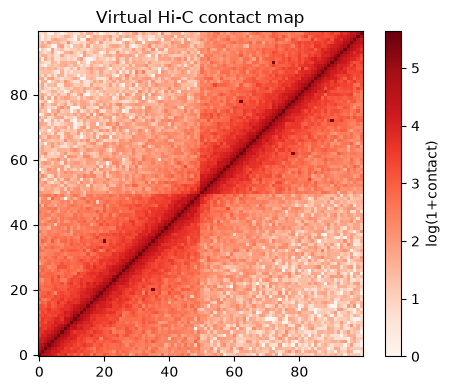

P(s) distance 1 mean contact 130.45
P(s) distance 2 mean contact 90.02
P(s) distance 5 mean contact 47.57
P(s) distance 10 mean contact 27.11
P(s) distance 20 mean contact 14.06
compartment recovery r 0.91
preset loop 20 35 raw 223 O/E 11.0
preset loop 62 78 raw 212 O/E 10.57
preset loop 72 90 raw 199 O/E 11.03
top local-background loop candidates
 local_enrichment  bin1  bin2    OE
            10.06    20    35 11.00
             9.99    62    78 10.57
             9.92    72    90 11.03
             3.19    10    93  2.49
             3.03    25    77  2.31
             2.98     5    79  2.89
             2.84    14    93  2.42
             2.83    27    86  2.64


In [2]:
import matplotlib.pyplot as plt
nbin=100; idx=np.arange(nbin); dist=np.abs(idx[:,None]-idx[None,:]); expected=180/(dist+1)**.9; comp=np.r_[np.ones(50),-np.ones(50)]; expected*=np.where(comp[:,None]==comp[None,:],1.35,.75); loops=[(20,35),(62,78),(72,90)];
for i,j in loops: expected[i,j]+=180; expected[j,i]+=180
upper=np.triu(rng.poisson(np.triu(expected))); C=upper+np.triu(upper,1).T; print('contact matrix',C.shape,'symmetric',bool(np.array_equal(C,C.T)),'zero fraction',round(np.mean(C==0),3)); plt.figure(figsize=(5,4)); plt.imshow(np.log1p(C),origin='lower',cmap='Reds'); plt.colorbar(label='log(1+contact)'); plt.title('Virtual Hi-C contact map'); plt.tight_layout(); plt.savefig('11_hic_contactmap.png',dpi=160,bbox_inches='tight'); plt.show()
for d in [1,2,5,10,20]: print('P(s) distance',d,'mean contact',round(float(np.diag(C,k=d).mean()),2))

# observed/expected按基因组距离校正，再用第一特征向量恢复compartment
OE=np.zeros_like(C,dtype=float)
for d in range(nbin):
 vals=np.diag(C,k=d); mu=max(vals.mean(),1e-6); ii=np.arange(nbin-d); OE[ii,ii+d]=C[ii,ii+d]/mu; OE[ii+d,ii]=OE[ii,ii+d]
cor=np.corrcoef(OE); val,vec=np.linalg.eigh(np.nan_to_num(cor)); pc=vec[:,-1]; pc*=np.sign(np.corrcoef(pc,comp)[0,1]); print('compartment recovery r',round(np.corrcoef(pc,comp)[0,1],3))
# loop局部富集：与相同距离期望比较
for i,j in loops: print('preset loop',i,j,'raw',C[i,j],'O/E',round(OE[i,j],2))
candidates=[]
for i in range(5,nbin-5):
 for j in range(i+8,nbin-5):
  local=OE[i-2:i+3,j-2:j+3].copy(); bg=(local.sum()-OE[i,j])/(local.size-1); enrich=OE[i,j]/max(bg,1e-6); candidates.append((enrich,i,j,OE[i,j]))
print('top local-background loop candidates')
print(pd.DataFrame(sorted(candidates,reverse=True)[:8],columns=['local_enrichment','bin1','bin2','OE']).round(2).to_string(index=False))


实践运行结果图11.1-1  固定种子生成的模拟Hi-C接触热图（横纵轴为模拟分箱，颜色表示ln(1+接触计数)）

结果解释：间距从1增至20个分箱时，平均接触计数由130.45降至14.06；O/E行相关矩阵的首特征向量与模拟区室的相关为0.910（按真值定向），但真实数据的特征向量正负号需借助活性标记定向。3个预设环的同距离O/E约10.57–11.03，局部邻域富集比约9.92–10.06，按后者排序居前三；这仍只说明接触富集，不证明功能因果。

可修改练习：移除一个预设环或把其附加计数期望由180降至60，比较对应坐标的排名。再改变区室倍率，比较特征向量恢复相关。